# Employee Attrition Prediction - Exploratory Data Analysis

**Objective:** Understand the IBM HR Analytics Employee Attrition dataset before building classification models.

- Dataset: 1470 employee records, 35 attributes
- Target: `Attrition` (binary: Yes / No)
- Business question: *What makes an employee leave?*

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/employee_attrition.csv")
print(f"Shape: {df.shape}")
df.head(8)

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,4,Male,79,3,1,Laboratory Technician,4,Single,3068,11864,0,Y,No,13,3,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,3,Female,81,4,1,Laboratory Technician,1,Married,2670,9964,4,Y,Yes,20,4,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,4,Male,67,3,1,Laboratory Technician,3,Divorced,2693,13335,1,Y,No,22,4,2,80,1,1,2,3,1,0,0,0


## 2. Data Types and Memory

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 3. Missing Values, Duplicates, Constant Columns

In [3]:
print("Missing values total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns (no predictive value):", constant_cols)

Missing values total: 0
Duplicate rows: 0
Constant columns (no predictive value): ['EmployeeCount', 'Over18', 'StandardHours']


## 4. Target Variable Distribution

Only **16.1%** of employees left the company. This is a **class imbalance** - accuracy alone will be misleading, so we must use precision, recall, F1 and ROC-AUC.

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition rate: 16.12%


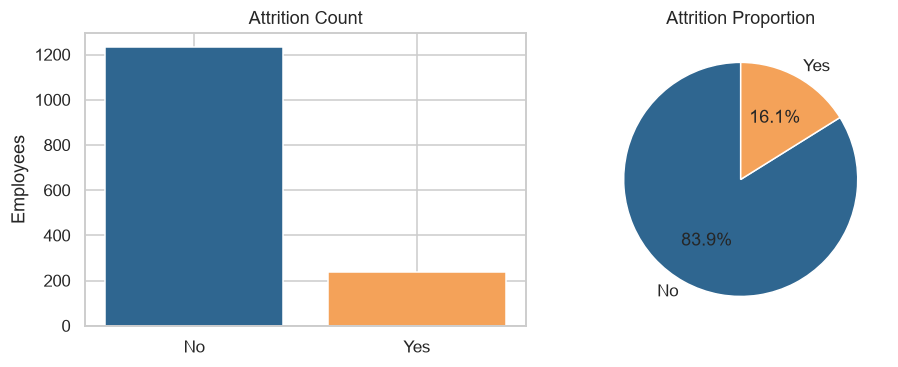

In [4]:
attrition_counts = df["Attrition"].value_counts()
print(attrition_counts)
print(f"Attrition rate: {attrition_counts['Yes'] / len(df):.2%}")

colors = ["#2f6690", "#f4a259"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].bar(attrition_counts.index, attrition_counts.values, color=colors)
ax[0].set_title("Attrition Count")
ax[0].set_ylabel("Employees")
patches, _, _ = ax[1].pie(attrition_counts.values, labels=attrition_counts.index,
                          autopct="%.1f%%", colors=colors, startangle=90)
ax[1].set_title("Attrition Proportion")
plt.tight_layout()
plt.show()

## 5. Categorical Features - Distribution

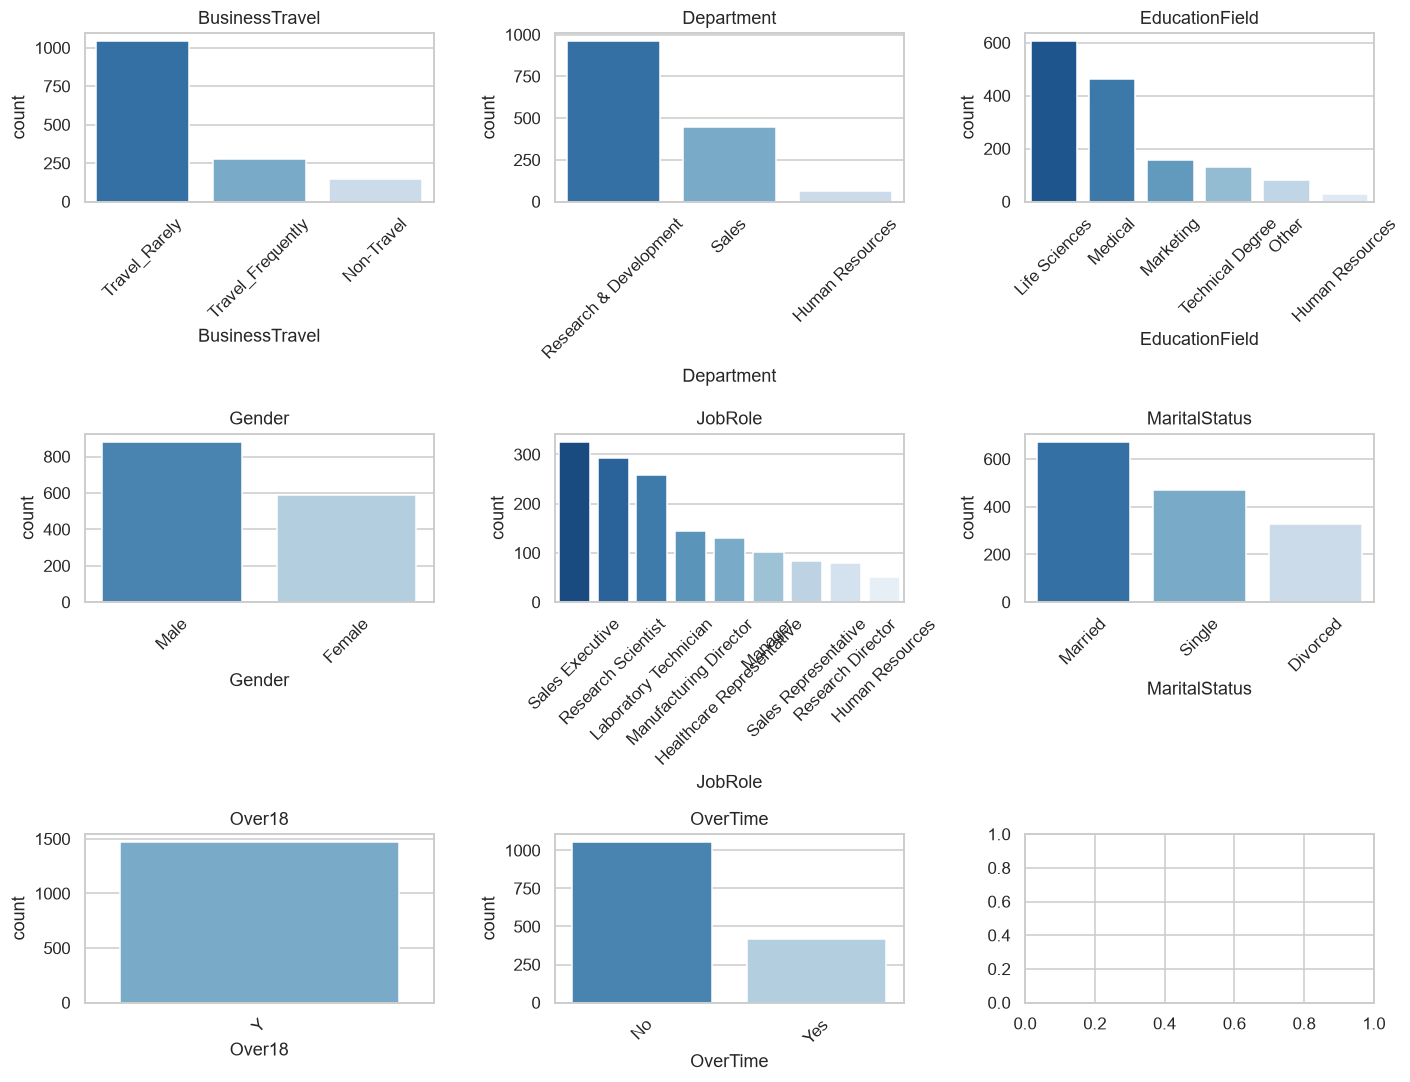

In [5]:
categorical_cols = df.select_dtypes(include="object").columns.drop("Attrition")
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
axes = axes.ravel()
for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i], palette="Blues_r")
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 6. Numeric Features - Summary Statistics

In [6]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


## 7. Attrition vs. Candidate Drivers

### 7.1 Overtime and Marital Status

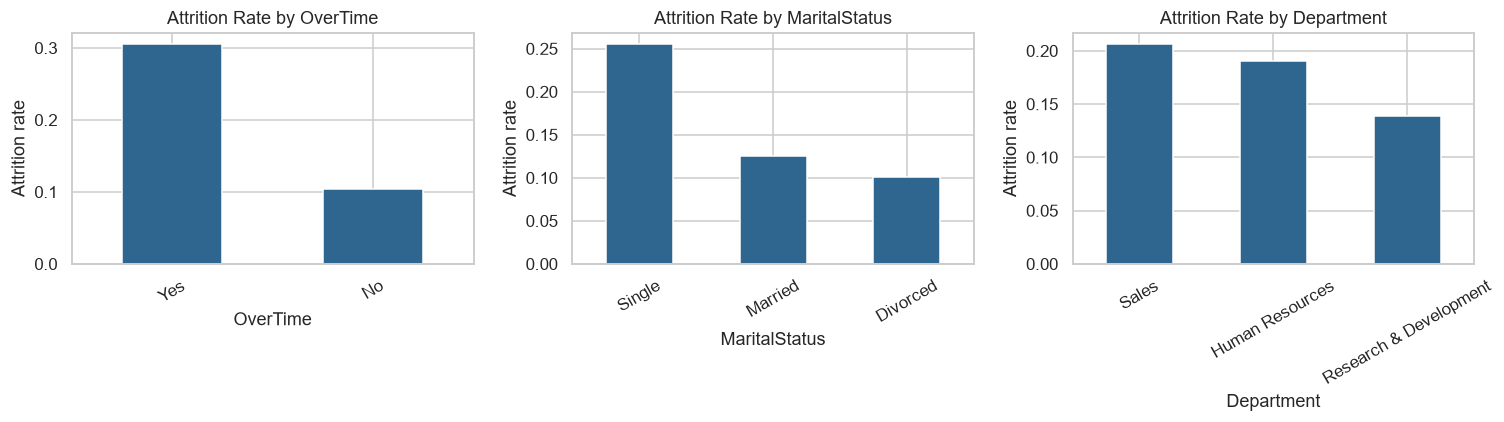

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["OverTime", "MaritalStatus", "Department"]):
    ct = pd.crosstab(df[col], df["Attrition"], normalize="index")["Yes"]
    ct.sort_values(ascending=False).plot(kind="bar", ax=ax, color="#2f6690")
    ax.set_title(f"Attrition Rate by {col}")
    ax.set_ylabel("Attrition rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 7.2 Satisfaction Levels (ordered Likert scales)

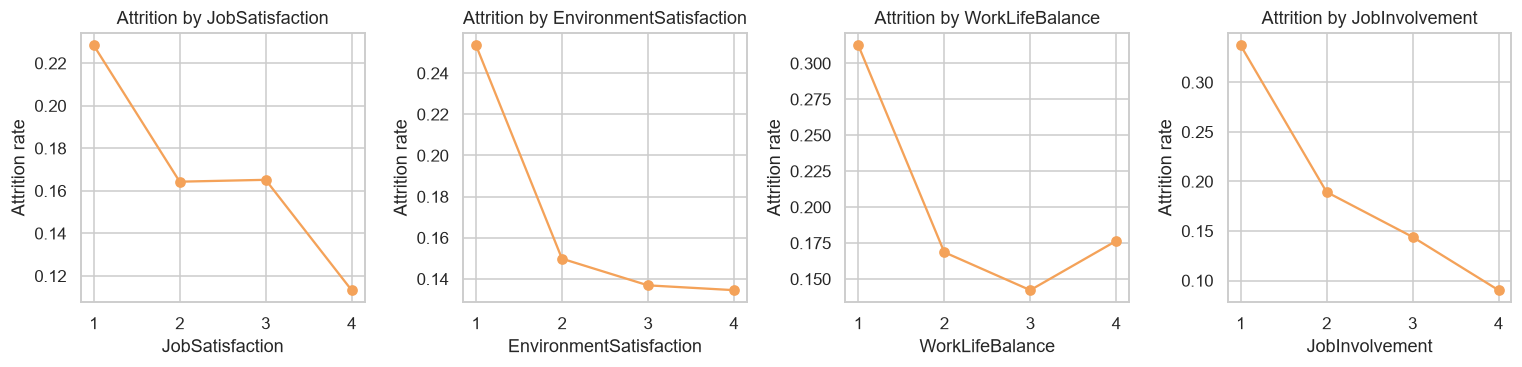

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement"]):
    rate = df.groupby(col)["Attrition"].apply(lambda s: (s == "Yes").mean())
    rate.plot(kind="line", marker="o", ax=ax, color="#f4a259")
    ax.set_title(f"Attrition by {col}")
    ax.set_ylabel("Attrition rate")
    ax.set_xticks(sorted(df[col].unique()))
plt.tight_layout()
plt.show()

### 7.3 Continuous Drivers: Age, Income, Distance From Home, Tenure

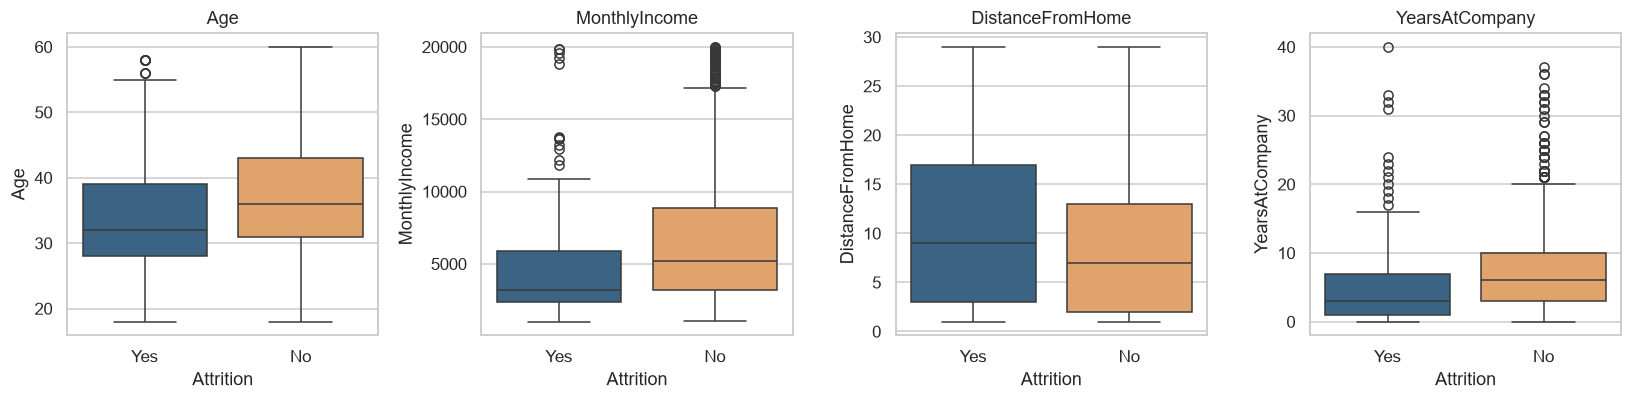

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
cont_cols = ["Age", "MonthlyIncome", "DistanceFromHome", "YearsAtCompany"]
for ax, col in zip(axes, cont_cols):
    sns.boxplot(data=df, x="Attrition", y=col, ax=ax, palette=["#2f6690", "#f4a259"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 7.4 Years in Current Role & Years Since Last Promotion

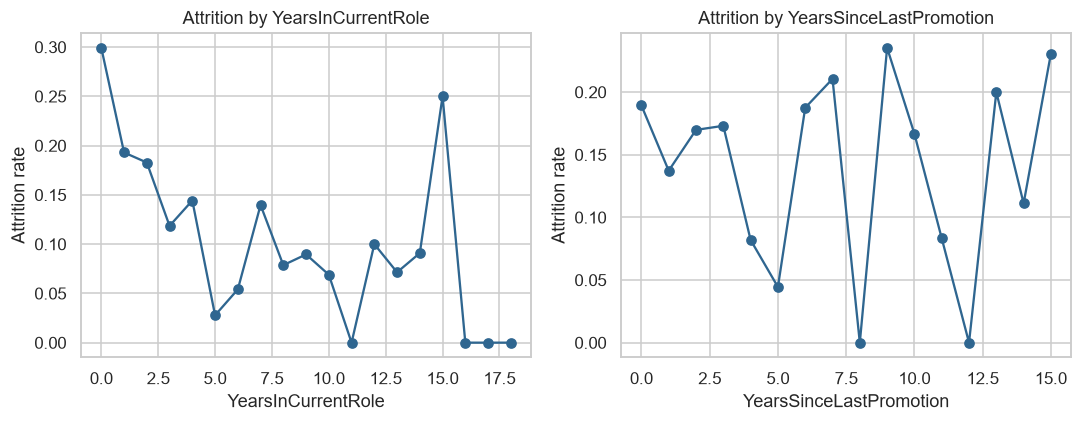

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["YearsInCurrentRole", "YearsSinceLastPromotion"]):
    rate = df.groupby(col)["Attrition"].apply(lambda s: (s == "Yes").mean())
    rate.plot(kind="line", marker="o", ax=ax, color="#2f6690")
    ax.set_title(f"Attrition by {col}")
    ax.set_ylabel("Attrition rate")
plt.tight_layout()
plt.show()

## 8. Correlation Heatmap (Numeric Features)

Top correlations with Attrition:
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
EmployeeNumber             -0.010577
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
Name: Attrition, dtype: float64


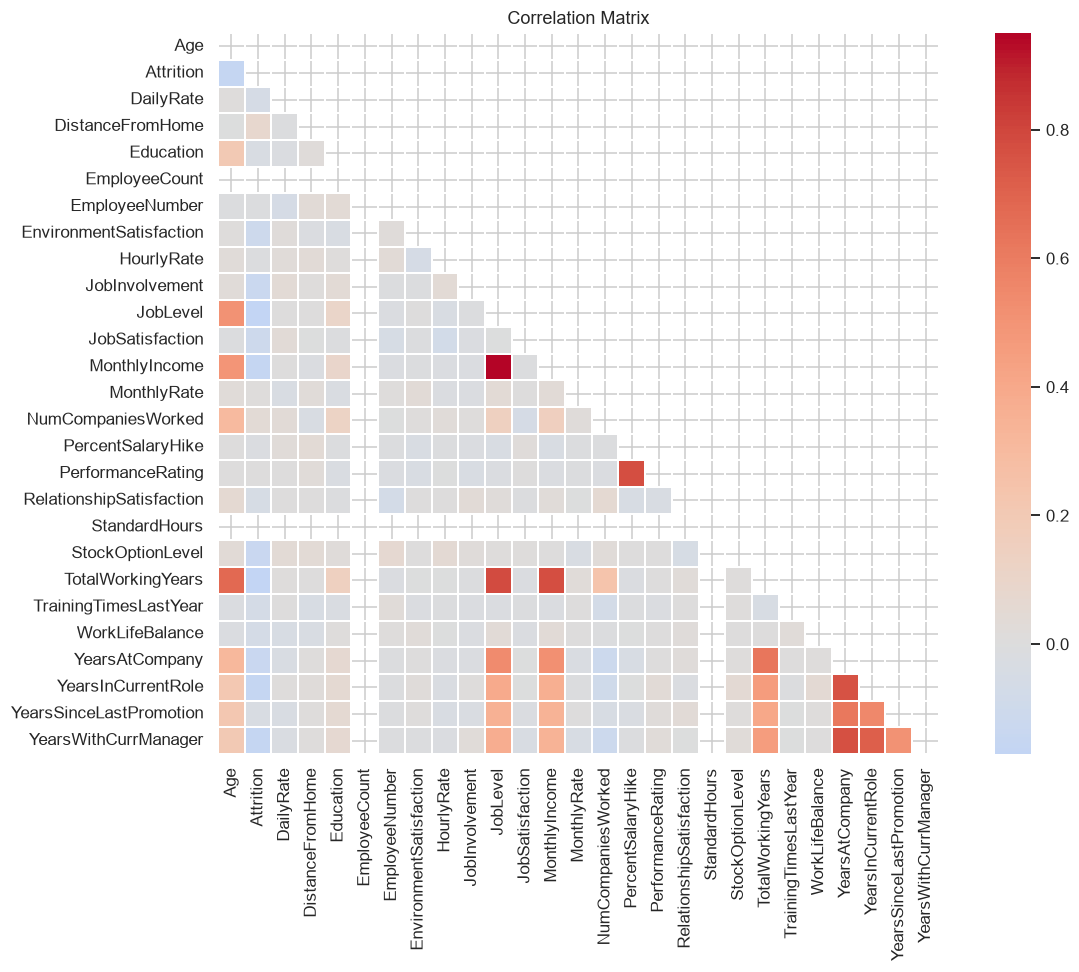

In [11]:
df_num = df.copy()
df_num["Attrition"] = (df_num["Attrition"] == "Yes").astype(int)
corr = df_num.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=False,
            square=True, linewidths=0.3, ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

target_corr = corr["Attrition"].drop("Attrition").sort_values(ascending=False)
print("Top correlations with Attrition:")
print(target_corr.head(10))

## 9. Key Insights

1. **Class imbalance:** Attrition is only ~16% -> evaluate with F1 / ROC-AUC, not accuracy only.
2. **Overtime is a strong categorical driver** - employees working overtime leave far more often.
3. **Low satisfaction** (job, environment, work-life balance) strongly increases attrition.
4. **Younger employees, low total working years, and shorter tenure** tend to leave more.
5. **Longer distance from home** correlates with higher attrition.
6. **Salary:** MonthlyIncome alone has weak raw correlation but strong interaction effects - tree/ensemble models capture this.
7. Constant/identity columns (`EmployeeNumber`, `EmployeeCount`, `Over18`, `StandardHours`) will be **dropped**.
8. No missing values and no duplicates - cleaning is minimal.

Next step: build a preprocessing pipeline (drop + one-hot encode + scale) **inside a scikit-learn Pipeline** to avoid data leakage, then train and compare 5 classifiers.